 Data Understanding & Audit

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [ ]:
df = pd.read_csv(r"C:\Users\ABC\OneDrive - Aditya Educational Institutions\Desktop\LifeTwin\LifeTwin\LifeTwin\data\raw\lifetwin_(2) (1).csv")

In [ ]:
df.head()

,user_id,record_date,age_group,day_of_week,sleep_hours,sleep_quality,wake_time_consistency,study_work_hours,focus_sessions,screen_time_hours,social_media_hours,notification_interruptions,exercise_minutes,step_count,stress_level,mood_score,energy_level,caffeine_intake,break_minutes,productivity_score
0,U094,2026-05-13,23-27,Wednesday,3.00,4.5,NaN,10.58,0.9,9.88,4.48,12.0,0.0,3776.0,NaN,3.2,1.0,NaN,10.0,24.7
1,U151,2026-07-14,18-22,Tuesday,6.83,5.5,6.8,3.31,4.0,10.61,6.54,67.0,18.0,3069.0,3.0,7.1,5.8,2.4,33.0,38.1
2,U209,2026-03-29,23-27,Sunday,7.79,7.0,4.5,1.23,1.8,6.83,4.63,106.0,23.0,1858.0,2.2,5.1,2.1,0.0,116.0,26.7
3,U088,2026-04-10,23-27,Friday,8.58,7.1,6.6,5.75,1.4,1.97,0.71,6.0,76.0,12300.0,2.4,8.8,6.9,0.3,114.0,69.9
4,U219,2026-05-21,18-22,Thursday,7.64,8.4,7.0,7.54,6.3,7.33,1.10,29.0,31.0,6814.0,4.2,7.6,6.9,0.5,79.0,65.6


In [ ]:
df.shape

(10000, 20)

In [ ]:
df.columns.tolist()

['user_id',
 'record_date',
 'age_group',
 'day_of_week',
 'sleep_hours',
 'sleep_quality',
 'wake_time_consistency',
 'study_work_hours',
 'focus_sessions',
 'screen_time_hours',
 'social_media_hours',
 'notification_interruptions',
 'exercise_minutes',
 'step_count',
 'stress_level',
 'mood_score',
 'energy_level',
 'caffeine_intake',
 'break_minutes',
 'productivity_score']

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   user_id                     10000 non-null  str    
 1   record_date                 10000 non-null  str    
 2   age_group                   10000 non-null  str    
 3   day_of_week                 10000 non-null  str    
 4   sleep_hours                 9600 non-null   float64
 5   sleep_quality               9678 non-null   float64
 6   wake_time_consistency       9524 non-null   float64
 7   study_work_hours            9513 non-null   float64
 8   focus_sessions              9531 non-null   float64
 9   screen_time_hours           9636 non-null   float64
 10  social_media_hours          9605 non-null   float64
 11  notification_interruptions  9728 non-null   float64
 12  exercise_minutes            9586 non-null   float64
 13  step_count                  9506 non-null  

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
sleep_hours,9600.0,6.603329,1.510131,3.0,5.56,6.70,7.68,10.50
sleep_quality,9678.0,5.607812,2.152279,1.0,4.10,5.70,7.20,10.00
wake_time_consistency,9524.0,5.288587,2.408686,1.0,3.50,5.30,7.10,10.00
study_work_hours,9513.0,5.878999,3.137055,0.0,3.58,5.75,8.03,14.00
focus_sessions,9531.0,3.798793,2.376577,0.0,2.00,3.70,5.50,10.00
screen_time_hours,9636.0,7.169208,2.638345,1.0,5.23,7.03,8.97,16.00
social_media_hours,9605.0,2.498347,1.913370,0.0,1.06,2.05,3.51,9.99
notification_interruptions,9728.0,46.841386,29.777604,0.0,24.00,42.00,65.00,150.00
exercise_minutes,9586.0,28.628521,23.984829,0.0,9.00,25.00,43.00,128.00
step_count,9506.0,5891.605302,2742.893744,505.0,3908.25,5549.00,7578.25,19944.00


In [ ]:
missing = df.isnull().sum()

missing[missing > 0].sort_values(ascending=False)

step_count                    494
mood_score                    490
study_work_hours              487
wake_time_consistency         476
focus_sessions                469
break_minutes                 453
exercise_minutes              414
sleep_hours                   400
social_media_hours            395
screen_time_hours             364
caffeine_intake               352
stress_level                  337
sleep_quality                 322
energy_level                  304
notification_interruptions    272
dtype: int64

In [ ]:
df.duplicated().sum()

np.int64(0)

## Data Quality Validation

We now validate numerical ranges and logical relationships
before deciding how missing values, invalid values, and
outliers should be handled.

In [ ]:
checks = {
    "sleep_hours": (0, 24),
    "sleep_quality": (1, 10),
    "wake_time_consistency": (1, 10),
    "study_work_hours": (0, 24),
    "focus_sessions": (0, None),
    "screen_time_hours": (0, 24),
    "social_media_hours": (0, 24),
    "notification_interruptions": (0, None),
    "exercise_minutes": (0, 1440),
    "step_count": (0, None),
    "stress_level": (1, 10),
    "mood_score": (1, 10),
    "energy_level": (1, 10),
    "caffeine_intake": (0, None),
    "break_minutes": (0, 1440),
    "productivity_score": (0, 100)
}

for col, (low, high) in checks.items():
    if low is not None:
        low_count = (df[col] < low).sum()
    else:
        low_count = 0

    if high is not None:
        high_count = (df[col] > high).sum()
    else:
        high_count = 0

    print(f"{col}: below={low_count}, above={high_count}")

sleep_hours: below=0, above=0
sleep_quality: below=0, above=0
wake_time_consistency: below=0, above=0
study_work_hours: below=0, above=0
focus_sessions: below=0, above=0
screen_time_hours: below=0, above=0
social_media_hours: below=0, above=0
notification_interruptions: below=0, above=0
exercise_minutes: below=0, above=0
step_count: below=0, above=0
stress_level: below=0, above=0
mood_score: below=0, above=0
energy_level: below=0, above=0
caffeine_intake: below=0, above=0
break_minutes: below=0, above=0
productivity_score: below=0, above=0


In [ ]:
invalid_screen_time = (
    df["social_media_hours"] > df["screen_time_hours"]
).sum()

print("Social media > screen time:", invalid_screen_time)

Social media > screen time: 0


In [ ]:
temp_date = pd.to_datetime(df["record_date"], errors="coerce")

print("Invalid dates:", temp_date.isna().sum())

expected_day = temp_date.dt.day_name()

day_mismatch = (
    expected_day != df["day_of_week"]
).sum()

print("Day-of-week mismatches:", day_mismatch)

Invalid dates: 0
Day-of-week mismatches: 0


In [ ]:
print("AGE GROUPS")
print(df["age_group"].value_counts(dropna=False))

print("\nDAY OF WEEK")
print(df["day_of_week"].value_counts(dropna=False))

print("\nUSER COUNT")
print(df["user_id"].nunique())

AGE GROUPS
age_group
18-22    5320
23-27    3320
28-35    1360
Name: count, dtype: int64

DAY OF WEEK
day_of_week
Sunday       1472
Saturday     1457
Monday       1436
Thursday     1423
Friday       1421
Wednesday    1398
Tuesday      1393
Name: count, dtype: int64

USER COUNT
250


 Productivity Score Distribution

The productivity score is the primary regression target.
We inspect its distribution before preprocessing and modeling.

In [ ]:
print(df["productivity_score"].describe())

count    10000.000000
mean        47.884670
std         18.219306
min          0.000000
25%         34.100000
50%         48.300000
75%         62.200000
max         94.300000
Name: productivity_score, dtype: float64


In [ ]:
print(df["productivity_score"].describe())

count    10000.000000
mean        47.884670
std         18.219306
min          0.000000
25%         34.100000
50%         48.300000
75%         62.200000
max         94.300000
Name: productivity_score, dtype: float64


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

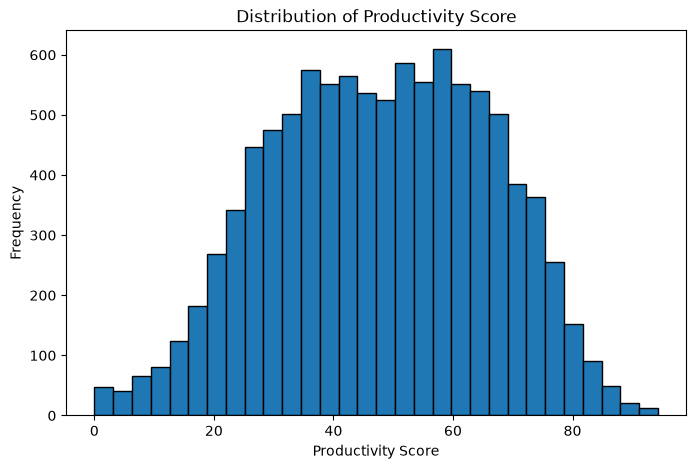

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["productivity_score"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Productivity Score")
plt.xlabel("Productivity Score")
plt.ylabel("Frequency")

plt.show()